<a href="https://colab.research.google.com/github/23070075-creator/NNDL-Lab/blob/main/NNDL_PRACTICAL_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from io import BytesIO
import requests

model_url = "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"
model = tf.saved_model.load(model_url)

image_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/grace_hopper.jpg"
image = Image.open(BytesIO(requests.get(image_url).content)).convert("RGB")
image = np.array(image)

input_tensor = tf.convert_to_tensor(image, dtype=tf.uint8)
input_tensor = input_tensor[tf.newaxis, ...]

detections = model(input_tensor)

boxes = detections["detection_boxes"][0].numpy()
scores = detections["detection_scores"][0].numpy()
classes = detections["detection_classes"][0].numpy().astype(int)

plt.figure(figsize=(10, 7))
plt.imshow(image)
height, width, _ = image.shape

for i in range(len(scores)):
    if scores[i] > 0.5:
        ymin, xmin, ymax, xmax = boxes[i]
        plt.gca().add_patch(
            plt.Rectangle(
                (xmin * width, ymin * height),
                (xmax - xmin) * width,
                (ymax - ymin) * height,
                fill=False, edgecolor="red", linewidth=2
            )
        )
        plt.text(
            xmin * width, ymin * height,
            f"Class {classes[i]}: {scores[i]:.2f}",
            color="white",
            bbox=dict(facecolor="red")
        )

plt.axis("off")
plt.show()

UnimplementedError: File system scheme 'https' not implemented (file: 'https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2/saved_model.pb')

In [2]:

from google.colab import files

uploaded = files.upload()

Saving istockphoto-2149306940-612x612.jpg to istockphoto-2149306940-612x612.jpg


In [4]:

!pip install -q tensorflow-hub


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Saving istockphoto-2149306940-612x612.jpg to istockphoto-2149306940-612x612 (1).jpg


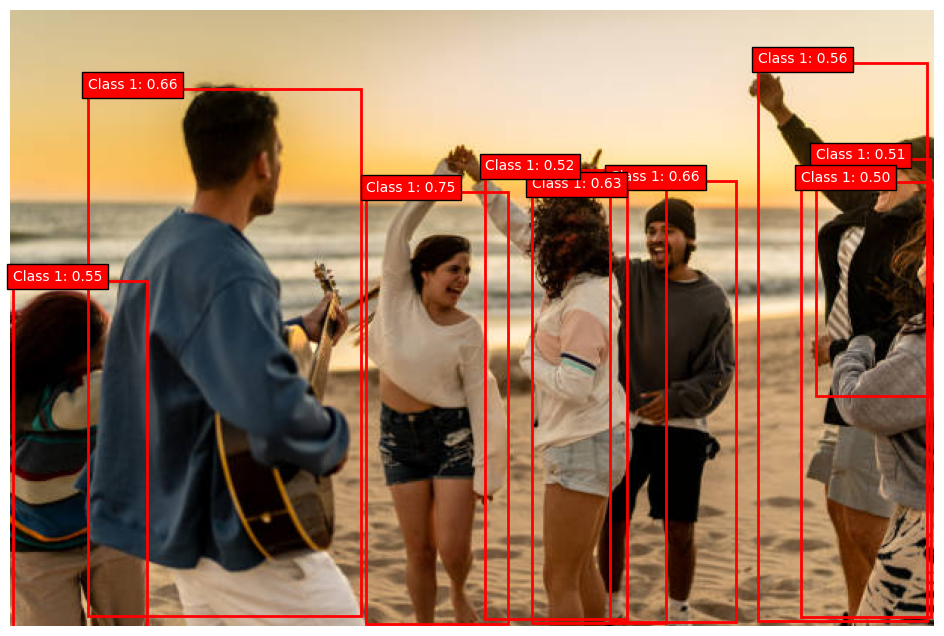

In [5]:

import tensorflow as tf
import tensorflow_hub as hub
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]
image = Image.open(image_path).convert("RGB")
image = np.array(image)

model_url = "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"
model = hub.load(model_url)

input_tensor = tf.convert_to_tensor(image, dtype=tf.uint8)
input_tensor = input_tensor[tf.newaxis, ...]

detections = model(input_tensor)

boxes = detections["detection_boxes"][0].numpy()
scores = detections["detection_scores"][0].numpy()
classes = detections["detection_classes"][0].numpy().astype(int)

plt.figure(figsize=(12, 8))
plt.imshow(image)

height, width, _ = image.shape
ax = plt.gca()

for i in range(len(scores)):
    if scores[i] > 0.5:
        ymin, xmin, ymax, xmax = boxes[i]

        rect = plt.Rectangle(
            (xmin * width, ymin * height),
            (xmax - xmin) * width,
            (ymax - ymin) * height,
            fill=False,
            edgecolor="red",
            linewidth=2
        )

        ax.add_patch(rect)

        ax.text(
            xmin * width,
            ymin * height,
            f"Class {classes[i]}: {scores[i]:.2f}",
            color="white",
            bbox=dict(facecolor="red")
        )

plt.axis("off")
plt.show()